# Background

- **Author**: 待學生填寫（已詢問）
- **Created At**: 2026-11-07
- **Research Motivation and Context (why are we interested in the findings?)：** 比較 MA 與 MS 州在各自收入四分位組內，白人、亞洲人與黑人的房貸核准率。使用學生指定的 [state_MA-MS_income_15_columns.csv](../data/processed/state_MA-MS_income_15_columns.csv)，[資料驗證文件](../data/processed/state_MA-MS_income_documentation.ipynb)。房貸檔無年份，故不標示其資料年份；門檻資料為 2024 ACS。另讀取 [income_quartiles_2024.csv](../data/processed/income_quartiles_2024.csv)，其產生程式為 [calculate_income_quartiles.py](../data/code/calculate_income_quartiles.py)。
- **Main Findings and Takeaways：** 本次使用 `income_quartiles_2024.csv` 中各州 2024 ACS 家戶收入門檻（美元）：MA 50,254.875／104,570.75／187,821.25；MS 28,427／59,493.65／107,514.975。房貸申請依這些界線分組；各組申請數不必各占 25%。實際執行結果顯示：除 Q1 亞洲人（MA 42.5%、MS 48.3%）以外，其餘 11 個收入組／種族組合的 MA 核准率皆高於 MS。Q1 的 MS 亞洲人僅 58 筆，區間較寬。各組與種族的完整核准率見下方四張圖與結果摘要；以上皆為描述性比較。
- **Future Direction：** 若需解釋差距，可再考慮貸款種類、用途等因素；本次圖表僅作描述，不推論種族或州別的因果效果。


In [1]:
# Load packages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib import font_manager
from IPython.display import Markdown
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Heiti TC', 'Arial Unicode MS', 'Noto Sans CJK TC'] if f in available_fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 11


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents) if (p / 'AGENTS.md').is_file() and (p / 'templates').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('請從 econ-5166-student-kit 或其子目錄執行。')
INPUT_PATH = 'data/processed/state_MA-MS_income_15_columns.csv'
EXPECTED_SHA256 = 'f466ff6c5ee8694b6a45e5d493dc38401cb75bc745131a6cb2f2b294190a4369'
input_file = (PROJECT_ROOT / INPUT_PATH).resolve()
assert input_file.is_relative_to((PROJECT_ROOT / 'data/processed').resolve())
if hashlib.sha256(input_file.read_bytes()).hexdigest() != EXPECTED_SHA256:
    raise ValueError('資料版本已改變，請先核對資料來源。')
df = pd.read_csv(input_file)

# 僅做簡單篩選與少量變數產生，不覆寫輸入。
assert df.shape == (237047, 15)
assert {'state_code','derived_race','income','action_taken'} <= set(df.columns)
assert set(df.state_code) == {'MA','MS'}
assert set(df.action_taken) == {1,2,3}
display(df.head(10))

# Bind the separately verified ACS household-income thresholds (USD).
QUARTILE_INPUT_PATH = 'data/processed/income_quartiles_2024.csv'
QUARTILE_SHA256 = '373fbf9fb3792b4fecdf442cbe50c93c17e2cbd9fe522e716746f219846e74bc'
quartile_file = (PROJECT_ROOT / QUARTILE_INPUT_PATH).resolve()
assert quartile_file.is_relative_to((PROJECT_ROOT / 'data/processed').resolve())
if hashlib.sha256(quartile_file.read_bytes()).hexdigest() != QUARTILE_SHA256:
    raise ValueError('ACS 收入門檻檔案版本已變更，請先核對。')
quartile_source = pd.read_csv(quartile_file)
assert len(quartile_source)==2 and quartile_source.state.is_unique
assert set(quartile_source.state)=={'MA','MS'}
assert {'state','Q1','Median','Q3'} <= set(quartile_source.columns)
assert (quartile_source.Q1 < quartile_source.Median).all()
assert (quartile_source.Median < quartile_source.Q3).all()
print('收入門檻原始資料（美元）：')
display(quartile_source)


,state_code,county_code,derived_ethnicity,derived_race,derived_sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,property_value,occupancy_type,income,debt_to_income_ratio,applicant_age
0,MA,25023.0,Not Hispanic or Latino,Black or African American,Male,1,1,1,605000.0,95.00000,635000,1,147.0,45,25-34
1,MS,28071.0,Not Hispanic or Latino,White,Female,1,2,32,125000.0,57.80000,205000,1,44.0,20%-<30%,65-74
2,MS,28059.0,Ethnicity Not Available,Race Not Available,Sex Not Available,1,3,1,185000.0,99.99900,185000,1,83.0,40,35-44
3,MA,25021.0,Not Hispanic or Latino,Black or African American,Female,3,2,32,245000.0,77.42000,315000,1,73.0,>60%,35-44
4,MS,28049.0,Not Hispanic or Latino,White,Joint,1,2,1,335000.0,89.62600,365000,1,94.0,30%-<36%,35-44
5,MS,28035.0,Not Hispanic or Latino,White,Male,1,3,1,295000.0,100.00000,285000,1,74.0,50%-60%,65-74
6,MS,28049.0,Not Hispanic or Latino,White,Male,1,2,32,295000.0,80.00000,355000,1,110.0,38,25-34
7,MA,25027.0,Not Hispanic or Latino,White,Joint,1,3,31,395000.0,NaN,NaN,1,NaN,NaN,25-34
8,MA,25023.0,Not Hispanic or Latino,White,Joint,2,2,31,485000.0,NaN,NaN,1,NaN,NaN,45-54
9,MS,28047.0,Not Hispanic or Latino,White,Joint,1,3,31,315000.0,NaN,NaN,1,NaN,NaN,35-44


收入門檻原始資料（美元）：


,state,state_fips,sample_size_before_cleaning,sample_size_after_cleaning,estimated_households,Q1,Median,Q3,IQR
0,MA,25,36522,29115,2829808,50254.875,104570.75,187821.250,137566.375
1,MS,28,15361,12242,1176687,28427.000,59493.65,107514.975,79087.975


## 樣本與定義

- 核准：`action_taken ∈ {1,2}`；拒絕：`action_taken = 3`。核准率 = 核准筆數 /（核准＋拒絕筆數）。核准不等同於實際撥款。
- 四分位門檻：依使用者指定，直接使用 `income_quartiles_2024.csv` 中各州的 Q1、Median、Q3（2024 ACS 加權家戶年收入四分位數，單位為美元）。這些界線對同州所有種族相同；不從房貸資料重新估計門檻，也不按種族重算。
- 單位換算：房貸 `income` 為千美元，ACS 門檻為美元，因此將 ACS 門檻除以 1,000 後與房貸收入比較；例如 MA 的 P25 為 50,254.875 美元，等於 50.254875 千美元。
- Q1：收入 ≤ P25；Q2：P25 < 收入 ≤ P50；Q3：P50 < 收入 ≤ P75；Q4：收入 > P75。同收入者留在同一組，因此房貸申請的各組筆數不必占 25%；四分位數描述的是 ACS 家戶收入分布。
- 收入缺失／非有限值無法分組，排除並列出筆數；保留有效的零與負收入，不任意刪除極端值。無申請識別碼，故不依 15 欄完全相同就去重。
- 繪圖只保留 `derived_race` 的 White、Asian、Black or African American。這是檔案提供的彙整種族分類；不額外限制族裔、貸款類型、用途或自住條件，不加權。
- 收入單位依 [HMDA 官方欄位定義](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields/)為千美元。原檔下載來源與年份未提供，欄位對照不代表已驗證來源或年份。


In [3]:
# Summary statistics before analysis: every variable actually used
print(f'表 1：來源檔收入摘要（總 N={len(df):,}；N 為有效數值筆數）')
income_numeric = pd.to_numeric(df['income'], errors='coerce')
finite = income_numeric.notna() & np.isfinite(income_numeric)
display(income_numeric[finite].describe().rename(index={'count':'N','mean':'平均','std':'標準差','min':'最小值','25%':'第25百分位','50%':'中位數','75%':'第75百分位','max':'最大值'}).to_frame('年收入（千美元）'))
print('收入缺失／非有限值：', int((~finite).sum()))
for col, label in [('state_code','州別'),('derived_race','種族'),('action_taken','申請結果')]:
    counts = df[col].value_counts(dropna=True)
    print(f'表 2：{label}（有效 N={counts.sum():,}；缺失 N={df[col].isna().sum():,}）')
    display(pd.DataFrame({'筆數':counts, '比例 (%)':counts / counts.sum() * 100}))

print('門檻來源資料摘要（各州一列，共 N=2；年收入門檻單位為美元）')
display(quartile_source[['Q1','Median','Q3']].describe().T)
print('州別：MA 與 MS 各 1 列、各占 50%；必要門檻欄位缺失數：')
display(quartile_source[['state','Q1','Median','Q3']].isna().sum().to_frame('缺失數'))


表 1：來源檔收入摘要（總 N=237,047；N 為有效數值筆數）


,年收入（千美元）
N,222427.000000
平均,161.255877
標準差,486.291362
最小值,-5536.000000
第25百分位,72.000000
中位數,114.000000
第75百分位,182.000000
最大值,150000.000000


收入缺失／非有限值： 14620
表 2：州別（有效 N=237,047；缺失 N=0）


,筆數,比例 (%)
state_code,,
MA,159998,67.496319
MS,77049,32.503681


表 2：種族（有效 N=237,047；缺失 N=0）


,筆數,比例 (%)
derived_race,,
White,149260,62.966416
Race Not Available,37554,15.842428
Black or African American,31370,13.233663
Asian,12773,5.388383
Joint,4313,1.819470
American Indian or Alaska Native,850,0.358579
2 or more minority races,448,0.188992
Native Hawaiian or Other Pacific Islander,394,0.166212
Free Form Text Only,85,0.035858


... (2 outputs left out)

門檻來源資料摘要（各州一列，共 N=2；年收入門檻單位為美元）


,count,mean,std,min,25%,50%,75%,max
Q1,2.0,39340.9375,15434.638431,28427.000,33883.96875,39340.9375,44797.90625,50254.875
Median,2.0,82032.2000,31874.323086,59493.650,70762.92500,82032.2000,93301.47500,104570.750
Q3,2.0,147668.1125,56785.111624,107514.975,127591.54375,147668.1125,167744.68125,187821.250


州別：MA 與 MS 各 1 列、各占 50%；必要門檻欄位缺失數：


,缺失數
state,0
Q1,0
Median,0
Q3,0


### The actual analysis starts below

In [4]:
eligible = df.loc[df.action_taken.isin([1,2,3]) & finite].copy()
eligible['income'] = income_numeric.loc[eligible.index]
eligible['approved'] = eligible.action_taken.isin([1,2]).astype(int)
cutoffs = quartile_source.set_index('state')[['Q1','Median','Q3']].rename(columns={'Q1':'P25','Median':'P50','Q3':'P75'}).reindex(['MA','MS']) / 1000
cutoffs.index.name = 'state_code'
assert (cutoffs.P25 < cutoffs.P50).all() and (cutoffs.P50 < cutoffs.P75).all()
eligible['income_quartile'] = pd.Series(index=eligible.index, dtype='string')
for state in ['MA','MS']:
    mask = eligible.state_code.eq(state)
    boundaries = [-np.inf, *cutoffs.loc[state].tolist(), np.inf]
    eligible.loc[mask,'income_quartile'] = pd.cut(eligible.loc[mask,'income'], boundaries, labels=['Q1','Q2','Q3','Q4'], right=True).astype('string')
assert eligible.income_quartile.notna().all()
print('表 3：各州 ACS 家戶收入門檻（已換算為千美元）；申請紀錄數僅描述本次收入有效的貸款樣本，不用於計算門檻')
display(cutoffs.join(eligible.groupby('state_code').size().rename('有效收入申請數')))
races = ['White','Asian','Black or African American']
analysis = eligible.loc[eligible.derived_race.isin(races)].copy()
print(f'表 4：三種族繪圖樣本 N={len(analysis):,}；排除其他種族 {len(eligible)-len(analysis):,} 筆')
display(pd.crosstab(analysis.state_code,analysis.income_quartile))
print('表 5：衍生變數摘要（分母為繪圖樣本非缺失數）')
for col in ['approved','income_quartile']:
    counts = analysis[col].value_counts(dropna=True).sort_index()
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts / counts.sum()*100}))
display(analysis[['income','approved']].describe().T)


表 3：各州 ACS 家戶收入門檻（已換算為千美元）；申請紀錄數僅描述本次收入有效的貸款樣本，不用於計算門檻


,P25,P50,P75,有效收入申請數
state_code,,,,
MA,50.254875,104.57075,187.821250,151564
MS,28.427000,59.49365,107.514975,70863


表 4：三種族繪圖樣本 N=187,943；排除其他種族 34,484 筆


income_quartile,Q1,Q2,Q3,Q4
state_code,,,,
MA,8547,33980,44689,37501
MS,4035,17917,22626,18648


表 5：衍生變數摘要（分母為繪圖樣本非缺失數）


,筆數,比例 (%)
approved,,
0,46213,24.588838
1,141730,75.411162


,筆數,比例 (%)
income_quartile,,
Q1,12582,6.694583
Q2,51897,27.613159
Q3,67315,35.81671
Q4,56149,29.875547


,count,mean,std,min,25%,50%,75%,max
income,187943.0,159.349915,514.155566,-2076.0,71.0,112.0,180.0,150000.0
approved,187943.0,0.754112,0.430614,0.0,1.0,1.0,1.0,1.0


In [5]:
# Wilson 95% intervals: descriptive binomial intervals, no lender clustering
idx = pd.MultiIndex.from_product([['Q1','Q2','Q3','Q4'],['MA','MS'],races],names=['income_quartile','state_code','derived_race'])
summary = analysis.groupby(['income_quartile','state_code','derived_race']).agg(approved_n=('approved','sum'),n=('approved','size')).reindex(idx)
summary[['approved_n','n']] = summary[['approved_n','n']].fillna(0).astype(int)
summary['denied_n'] = summary.n-summary.approved_n
summary['approval_rate'] = summary.approved_n / summary.n.replace(0,np.nan)
z=1.959963984540054
n=summary.n.replace(0,np.nan)
p=summary.approval_rate
den=1+z*z/n
center=(p+z*z/(2*n))/den
half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
summary['ci95_low']=(center-half).clip(0,1)
summary['ci95_high']=(center+half).clip(0,1)
assert summary.n.sum()==len(analysis)
assert summary.approved_n.sum()==analysis.approved.sum()
valid = summary.n.gt(0)
assert summary.loc[valid,'approval_rate'].between(0,1).all()
assert (summary.loc[valid,'ci95_low'] <= summary.loc[valid,'approval_rate']+1e-12).all()
assert (summary.loc[valid,'ci95_high'] >= summary.loc[valid,'approval_rate']-1e-12).all()
print(f'表 6：各收入組、州、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N={len(analysis):,}）')
display(summary)
assets=PROJECT_ROOT/'finding/assets/ma_ms_mortgage_approval'
assets.mkdir(parents=True,exist_ok=True)
summary.to_csv(assets/'approval_rates.csv')
cutoffs.to_csv(assets/'income_quartile_thresholds.csv')
# Reopen serialized result tables and verify their counts and values.
saved=pd.read_csv(assets/'approval_rates.csv')
assert len(saved)==24 and saved.n.sum()==len(analysis)
assert np.allclose(saved.approval_rate, summary.approval_rate, equal_nan=True)
assert np.allclose(pd.read_csv(assets/'income_quartile_thresholds.csv',index_col=0),cutoffs)


表 6：各收入組、州、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N=187,943）


approved_n      n  \
income_quartile state_code derived_race                                   
Q1              MA         White                            3433   7192   
                           Asian                             235    553   
                           Black or African American         221    802   
                MS         White                             918   2087   
                           Asian                              28     58   
                           Black or African American         475   1890   
Q2              MA         White                           20636  27913   
                           Asian                            1446   2068   
                           Black or African American        2398   3999   
                MS         White                            6692  10105   
                           Asian                             120    189   
                           Black or African American        3637   7623   
Q3              MA         White                           30321  36368   
                           Asian                            3333   4031   
                           Black or African American        3082   4290   
                MS         White                           12055  15368   
                           Asian                             247    334   
                           Black or African American        4320   6924   
Q4              MA         White                           27652  31393   
                           Asian                            4078   4660   
                           Black or African American        1037   1448   
                MS         White                           12831  14999   
                           Asian                             324    393   
                           Black or African American        2211   3256   

                                                      denied_n  approval_rate  \
income_quartile state_code derived_race                                         
Q1              MA         White                          3759       0.477336   
                           Asian                           318       0.424955   
                           Black or African American       581       0.275561   
                MS         White                          1169       0.439866   
                           Asian                            30       0.482759   
                           Black or African American      1415       0.251323   
Q2              MA         White                          7277       0.739297   
                           Asian                           622       0.699226   
                           Black or African American      1601       0.599650   
                MS         White                          3413       0.662246   
                           Asian                            69       0.634921   
                           Black or African American      3986       0.477109   
Q3              MA         White                          6047       0.833727   
                           Asian                           698       0.826842   
                           Black or African American      1208       0.718415   
                MS         White                          3313       0.784422   
                           Asian                            87       0.739521   
                           Black or African American      2604       0.623917   
Q4              MA         White                          3741       0.880833   
                           Asian                           582       0.875107   
                           Black or African American       411       0.716160   
                MS         White                          2168       0.855457   
                           Asian                            69       0.824427   
                           Black or African American      1045       0.679054 

## 四張收入組比較圖

長條為核准率，誤差線為 Wilson 95% 信賴區間，`n` 為該州／種族／收入組的核准加拒絕筆數。區間以申請紀錄互相獨立的二項模型計算，未調整同一貸款機構或重複申請的相關性；這些區間用於描述，不能視為已控制混淆因素的差距檢定。

各州的實際收入界線列於橫軸；相同 Q 組表示相對於各州 2024 ACS 家戶收入分布的位置，並不表示兩州收入金額相同。四張圖顏色與縱軸一致。


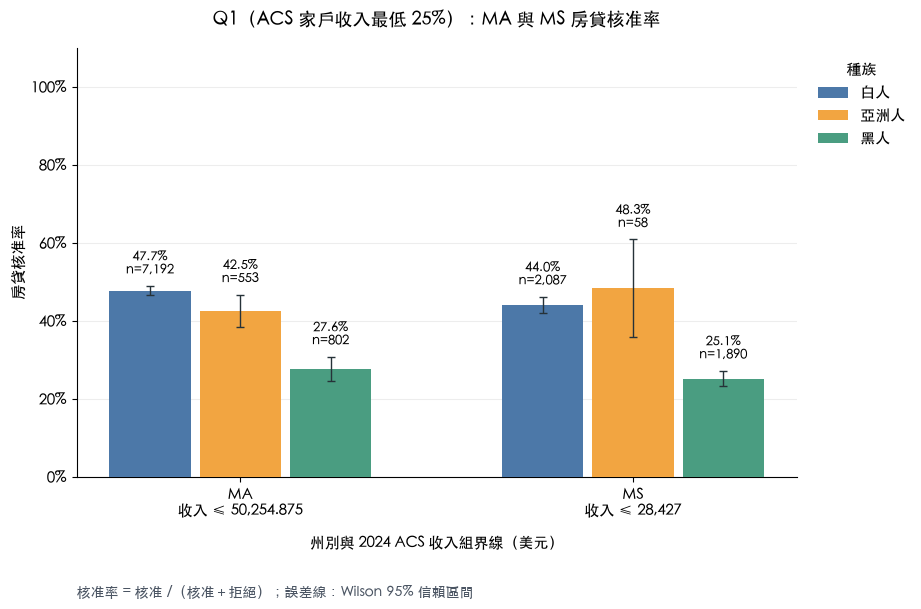

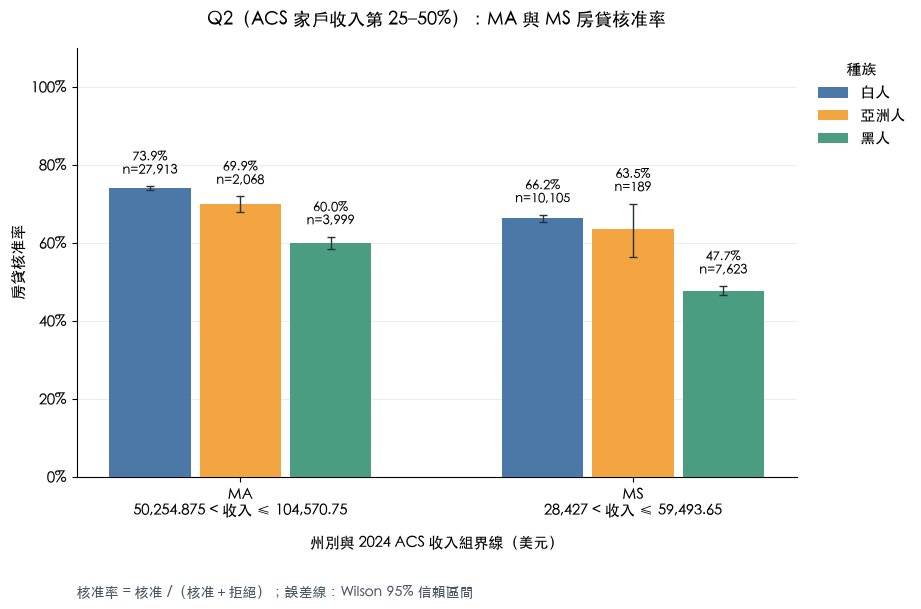

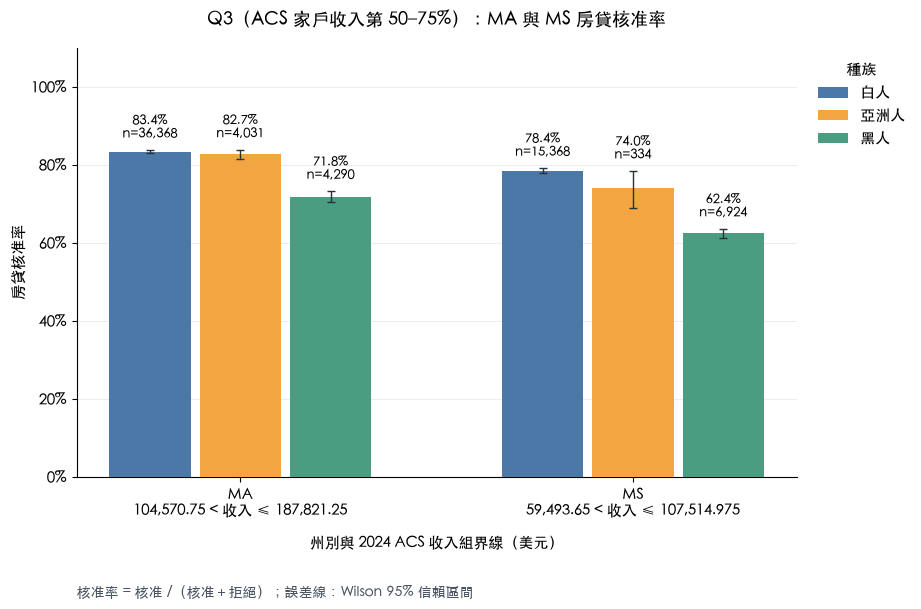

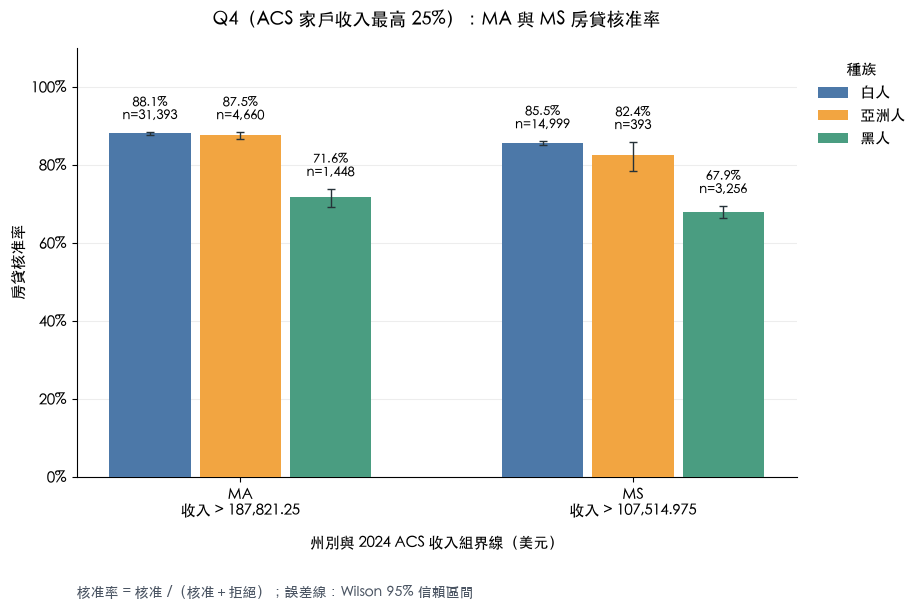

In [6]:
colors=['#4C78A8','#F2A541','#4A9D81']
race_labels=['白人','亞洲人','黑人']
quartile_labels={'Q1':'ACS 家戶收入最低 25%','Q2':'ACS 家戶收入第 25–50%','Q3':'ACS 家戶收入第 50–75%','Q4':'ACS 家戶收入最高 25%'}
def income_range(state,q):
    a,b,c=[f'{v*1000:,.3f}'.rstrip('0').rstrip('.') for v in cutoffs.loc[state]]
    return {'Q1':f'收入 ≤ {a}', 'Q2':f'{a} < 收入 ≤ {b}', 'Q3':f'{b} < 收入 ≤ {c}', 'Q4':f'收入 > {c}'}[q]
def draw_chart(ax,q):
    width=.23
    for j,(race,label,color) in enumerate(zip(races,race_labels,colors)):
        group=summary.xs((q,race),level=('income_quartile','derived_race')).reindex(['MA','MS'])
        x=np.arange(2)+(j-1)*width
        for k,row in enumerate(group.itertuples()):
            if row.n==0:
                ax.text(x[k],.025,'無樣本',ha='center',fontsize=9)
                continue
            ax.bar(x[k],row.approval_rate,width*.9,color=color,label=label if k==0 else None,zorder=3)
            ax.errorbar(x[k],row.approval_rate,yerr=[[max(0,row.approval_rate-row.ci95_low)],[max(0,row.ci95_high-row.approval_rate)]],fmt='none',ecolor='#263238',capsize=3,lw=1,zorder=4)
            ax.text(x[k],min(.99,row.ci95_high+.025),f'{row.approval_rate:.1%}\nn={row.n:,}',ha='center',va='bottom',fontsize=9)
    ax.set_title(f'{q}（{quartile_labels[q]}）：MA 與 MS 房貸核准率',fontsize=13,pad=16)
    ax.set_xticks([0,1], [f'{s}\n{income_range(s,q)}' for s in ['MA','MS']])
    ax.set_xlabel('州別與 2024 ACS 收入組界線（美元）',labelpad=12)
    ax.set_ylabel('房貸核准率')
    ax.set_ylim(0,1.1)
    ax.set_yticks(np.arange(0,1.01,.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y',alpha=.22,zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(title='種族',loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
for q in ['Q1','Q2','Q3','Q4']:
    fig,ax=plt.subplots(figsize=(10,6.5))
    draw_chart(ax,q)
    fig.text(.1,.025,'核准率 = 核准 /（核准＋拒絕）；誤差線：Wilson 95% 信賴區間',fontsize=10,color='#4b5563')
    fig.subplots_adjust(left=.1,right=.82,bottom=.21,top=.87)
    fig.savefig(assets/f'{q}_approval_rate.png',dpi=180,facecolor='white')
    plt.show()
    plt.close(fig)
# A combined overview supports easy comparison; the four separate files are also saved.
fig,axes=plt.subplots(2,2,figsize=(19,13))
for ax,q in zip(axes.flat,['Q1','Q2','Q3','Q4']):
    draw_chart(ax,q)
fig.subplots_adjust(left=.06,right=.92,bottom=.13,top=.93,wspace=.44,hspace=.58)
fig.text(.06,.025,'門檻：income_quartiles_2024.csv（各州 2024 ACS 家戶收入）；核准 = action_taken 1、2；拒絕 = 3；誤差線：Wilson 95% 信賴區間',fontsize=12)
fig.savefig(assets/'all_quartiles.png',dpi=150,facecolor='white')
plt.close(fig)


## 結果與限制

以下逐組比較依指定的 2024 ACS 家戶收入門檻重新執行。門檻描述一般家戶，核准率的分母是房貸申請，兩者的觀測單位不同；各組申請比例不必為 25%。房貸資料年份尚未確認，跨期解讀需留意。資料為未加權申請紀錄，收入缺失者不包含於圖表；缺失情形可能影響各組組成。種族為 `derived_race` 的彙整分類，並非單一申請人原始種族欄位。各收入組並未控制貸款條件、信用狀況與機構差異，不能將觀察差距直接解讀為歧視或因果效果。


In [7]:
for q in ['Q1','Q2','Q3','Q4']:
    lines=[]
    for race,label in zip(races,race_labels):
        ma=summary.loc[(q,'MA',race),'approval_rate']
        ms=summary.loc[(q,'MS',race),'approval_rate']
        lines.append(f'{label}：MA {ma:.1%}、MS {ms:.1%}（MA−MS {(ma-ms)*100:+.1f} 個百分點）')
    display(Markdown(f'**{q}**：'+'；'.join(lines)+'。'))
print('執行完成：24 個組合、4 張獨立圖與 1 張總覽圖已儲存；結果表重新讀取核對通過。')

# Keep CSV copies beside this notebook; figures remain in the dedicated assets folder.
import shutil
for filename in ['approval_rates.csv','income_quartile_thresholds.csv']:
    destination = PROJECT_ROOT / 'finding' / filename
    shutil.copy2(assets / filename, destination)
    assert destination.read_bytes() == (assets / filename).read_bytes()
print('finding 資料夾內的結果表已同步更新；圖表保留在 assets/ma_ms_mortgage_approval。門檻表 P25/P50/P75 單位為千美元。')


**Q1**：白人：MA 47.7%、MS 44.0%（MA−MS +3.7 個百分點）；亞洲人：MA 42.5%、MS 48.3%（MA−MS -5.8 個百分點）；黑人：MA 27.6%、MS 25.1%（MA−MS +2.4 個百分點）。

**Q2**：白人：MA 73.9%、MS 66.2%（MA−MS +7.7 個百分點）；亞洲人：MA 69.9%、MS 63.5%（MA−MS +6.4 個百分點）；黑人：MA 60.0%、MS 47.7%（MA−MS +12.3 個百分點）。

**Q3**：白人：MA 83.4%、MS 78.4%（MA−MS +4.9 個百分點）；亞洲人：MA 82.7%、MS 74.0%（MA−MS +8.7 個百分點）；黑人：MA 71.8%、MS 62.4%（MA−MS +9.4 個百分點）。

**Q4**：白人：MA 88.1%、MS 85.5%（MA−MS +2.5 個百分點）；亞洲人：MA 87.5%、MS 82.4%（MA−MS +5.1 個百分點）；黑人：MA 71.6%、MS 67.9%（MA−MS +3.7 個百分點）。

執行完成：24 個組合、4 張獨立圖與 1 張總覽圖已儲存；結果表重新讀取核對通過。
finding 資料夾內的圖表與結果表已同步更新。門檻表 P25/P50/P75 單位為千美元。
